# 08 — Profit: does each removal list still pay once margins are applied? (cereal)

**Pipeline notebook:** 08 (work-plan step 7 of 10) · **Data:** cereal, estimation weeks 1–75 · **Models:** fitted in notebook 04 · **Lists:** built in notebook 07 (not rebuilt here)

Dunnhumby has no cost data, so margins are **assumed** (frozen specification): **35% for private label, 26% for national brands**, as a share of the shelf price.

**How profit is calculated, per purchase line:**

- cost = shelf value × (1 − margin), where shelf value = what the line would cost at full shelf price (`gross_value`, from notebook 01)
- profit = what the shopper paid (`sales_value`) − cost

So retailer discounts reduce profit automatically: a product sold 30% off with a 26% margin loses money on that sale. Each alternative's **profit per purchase occasion** is the average over weeks 1–75, exactly matching how notebooks 06–07 measured revenue per purchase occasion.

**What is reported:**

1. **Main result:** profit change of the three lists from notebook 07 (naive, pooled, segment), each scored under both models, at the assumed margins.
2. **Reference case:** the same with one margin (30%) for every product. It separates the effect of the private-label margin gap from everything else.
3. **Break-even:** because profit is linear in the private-label margin, the notebook reports the private-label margin at which each list's profit change is exactly zero (national-brand margin held at 26%). This shows how much the conclusion depends on the assumption.

The lists themselves are not changed: they were chosen on revenue in notebook 07, as specified.

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

INPUTS = Path("modelling_inputs_dunnhumby")
PROC   = Path("data/processed")
SEGS   = Path("step7_outputs")
PARAMS = Path("outputs/choice_models/model_params.json")
LISTF  = Path("outputs/removal_lists/removal_lists.csv")
OUT    = Path("outputs/profit"); OUT.mkdir(parents=True, exist_ok=True)
CAT, NSEG = "cereal", 4
M_PL, M_NB = 0.35, 0.26          # frozen specification
M_EQUAL = 0.30                   # reference case: one margin for every product

P = json.load(open(PARAMS)); EST_END = P["estimation_weeks"][1]
occ  = pd.read_parquet(INPUTS / f"choice_occasions_{CAT}.parquet")
aw   = pd.read_parquet(INPUTS / f"alt_week_{CAT}.parquet")
alts = pd.read_parquet(INPUTS / f"alternatives_{CAT}.parquet")
segs = pd.read_parquet(SEGS / "household_segments.parquet")[["household_key", "segment", "segment_placebo"]]
est  = occ[occ.week_no <= EST_END].merge(segs, on="household_key", how="inner")
lists = pd.read_csv(LISTF, dtype={"alt_id": str})

## 1. Revenue, shelf value and profit per purchase occasion, by alternative

In [2]:
lines = pd.read_parquet(PROC / f"lines_{CAT}.parquet")
sku = pd.read_parquet(PROC / f"sku_master_{CAT}.parquet")[["product_id", "alt_id"]]
L = lines[lines.week_no <= EST_END].merge(sku, on="product_id")
occ_alt = L.groupby(["household_key", "week_no", "alt_id"]).agg(spend=("sales_value", "sum"), shelf=("gross_value", "sum")).reset_index()

alt_ids = P["alt_ids"]; J = len(alt_ids); idx = {a: i for i, a in enumerate(alt_ids)}
A_ = alts.set_index("alt_id").loc[alt_ids]
PL, IS_TAIL = A_.is_private.values.astype(float), A_.is_tail.values
per = occ_alt.groupby("alt_id")[["spend", "shelf"]].mean().reindex(alt_ids)
per = per.fillna(per.median())
SPEND, SHELF = per.spend.values, per.shelf.values          # $ per purchase occasion

def profit_per_purchase(m_pl, m_nb):
    margin = np.where(PL == 1, m_pl, m_nb)
    return SPEND - SHELF * (1 - margin)

PROF = profit_per_purchase(M_PL, M_NB)
disc = 1 - SPEND / SHELF
t = pd.DataFrame({"private_label": PL.astype(bool), "spend": SPEND, "discount_share": disc, "profit": PROF, "core": ~IS_TAIL})
summary_alt = t[t.core].groupby("private_label").agg(products=("spend", "size"), spend_per_purchase=("spend", "mean"),
                                                      discount_share=("discount_share", "mean"), profit_per_purchase=("profit", "mean"),
                                                      loss_making=("profit", lambda x: int((x < 0).sum())))
print(f"Margins: private label {M_PL:.0%}, national brand {M_NB:.0%} of shelf price")
summary_alt.round(3)

Margins: private label 35%, national brand 26% of shelf price


,products,spend_per_purchase,discount_share,profit_per_purchase,loss_making
private_label,,,,,
False,150,3.363,0.173,0.319,38
True,57,2.171,0.095,0.606,0


## 2. The model calculator (same code as notebook 07), now returning any value per purchase

In [3]:
REF = idx[P["reference_alt"]]; asc_cols = [i for i in range(J) if i != REF]
aw["j"] = aw.alt_id.map(idx); NW = int(aw.week_no.max())
def grid(col):
    g = np.zeros((J, NW + 1)); g[aw.j, aw.week_no] = aw[col].fillna(0).values; return g
AVAIL = np.zeros((J, NW + 1), bool); AVAIL[aw.j, aw.week_no] = aw.available.values
PRICE, DISC, DISP = grid("price"), grid("disc_depth"), grid("display_share")

def design(A, w, s, segmented):
    asc = np.zeros((len(A), J - 1)); pos = {c: k for k, c in enumerate(asc_cols)}
    for r, a in enumerate(A):
        if a != REF: asc[r, pos[a]] = 1
    X = np.column_stack([PRICE[A, w], DISC[A, w], DISP[A, w]])
    if not segmented: return np.hstack([asc, X])
    B = np.zeros((len(A), NSEG * 3)); B[:, 3 * s:3 * s + 3] = X
    Q = np.zeros((len(A), NSEG - 1))
    if s > 0: Q[:, s - 1] = PL[A]
    return np.hstack([asc, B, Q])
def month(w): return int(((w - 1) // 4.35) % 12)

class Market:
    def __init__(self, name):
        m = P["models"][name]; segm = m["segmented"]; col = m["segment_column"]
        th = np.array(m["stage1_theta"]); b2 = m["stage2_params"]
        counts = est.groupby(["week_no", col]).size() if segm else est.groupby("week_no").size()
        self.cells = []
        for key, N in counts.items():
            w, s = (key[0], int(key[1]) - 1) if segm else (key, 0)
            A = np.where(AVAIL[:, w])[0]; V = design(A, w, s, segm) @ th
            k = f" | seg {s + 1}" if segm else ""
            c0 = b2[f"const{k}"] + (b2.get(f"month_{month(w)}", 0.0) if month(w) > 0 else 0.0)
            self.cells.append(dict(s=s, N=float(N), A=A, eV=np.exp(V - V.max()), vmax=V.max(), c0=c0, lam=b2[f"attractiveness{k}"]))
    def demand(self, removed=()):
        """Expected purchase occasions of every alternative, per segment, with `removed` taken out."""
        rm = np.zeros(J, bool); rm[list(removed)] = True; D = np.zeros((NSEG, J))
        for c in self.cells:
            keep = ~rm[c["A"]]; e = c["eV"][keep]; S = e.sum()
            b = 1 / (1 + np.exp(-(c["c0"] + c["lam"] * (c["vmax"] + np.log(S)))))
            D[c["s"], c["A"][keep]] += c["N"] * b * e / S
        return D

MKT = {name: Market(name) for name in ["pooled", "segment"]}
BASE = {n: m.demand() for n, m in MKT.items()}
LISTS = {name: [idx[a] for a in g.sort_values("order").alt_id] for name, g in lists.groupby("list")}
AFTER = {(ev, ln): MKT[ev].demand(L) for ev in MKT for ln, L in LISTS.items()}

# reconciliation with notebook 07 (revenue change must match)
t2 = pd.read_csv("outputs/removal_lists/table2_list_costs.csv")
for (ev, ln), D in AFTER.items():
    rc = ((D - BASE[ev]).sum(0) * SPEND).sum()
    ref = t2[(t2.list == ln) & (t2.scored_by == f"{ev} model")].revenue_change.iloc[0]
    assert abs(rc - ref) < 0.01, f"revenue does not reconcile for {ln} / {ev}"
print("Revenue changes reconcile exactly with notebook 07.")

Revenue changes reconcile exactly with notebook 07.


## 3. Table 3 — profit change of each list

In [4]:
def profit_table(prof, label):
    rows = []
    for (ev, ln), D in AFTER.items():
        dD = (D - BASE[ev]).sum(0); base_profit = (BASE[ev].sum(0) * prof).sum()
        dP = (dD * prof).sum()
        rows.append(dict(margins=label, list=ln, scored_by=f"{ev} model", base_profit=base_profit, profit_change=dP,
                         profit_change_pct=100 * dP / base_profit, revenue_change=(dD * SPEND).sum()))
    return pd.DataFrame(rows)

main = profit_table(PROF, f"PL {M_PL:.0%} / NB {M_NB:.0%} (main)")
equal = profit_table(profit_per_purchase(M_EQUAL, M_EQUAL), f"all {M_EQUAL:.0%} (reference)")
table3 = pd.concat([main, equal], ignore_index=True)
order = {"naive": 0, "pooled": 1, "segment": 2}
table3 = table3.sort_values(["margins", "scored_by", "list"], key=lambda c: c.map(order) if c.name == "list" else c).reset_index(drop=True)
table3.round(2)

,margins,list,scored_by,base_profit,profit_change,profit_change_pct,revenue_change
0,PL 35% / NB 26% (main),naive,pooled model,5325.62,-53.59,-1.01,76.34
1,PL 35% / NB 26% (main),pooled,pooled model,5325.62,-315.87,-5.93,1154.11
2,PL 35% / NB 26% (main),segment,pooled model,5325.62,-252.61,-4.74,1150.69
3,PL 35% / NB 26% (main),naive,segment model,5330.41,-53.97,-1.01,55.32
4,PL 35% / NB 26% (main),pooled,segment model,5330.41,-329.08,-6.17,990.67
5,PL 35% / NB 26% (main),segment,segment model,5330.41,-264.75,-4.97,999.73
6,all 30% (reference),naive,pooled model,6914.54,-29.86,-0.43,76.34
7,all 30% (reference),pooled,pooled model,6914.54,-23.00,-0.33,1154.11
8,all 30% (reference),segment,pooled model,6914.54,9.84,0.14,1150.69
9,all 30% (reference),naive,segment model,6918.30,-32.44,-0.47,55.32


## 4. Why does profit move differently from revenue? Where the removed demand goes

For each list (segment model), the purchases lost from the removed products are split into: moved to private label, moved to national brands, and lost from cereal.

In [5]:
rows = []
for ln, L in LISTS.items():
    dD = (AFTER[("segment", ln)] - BASE["segment"]).sum(0)
    removed = -dD[L].sum(); to_pl = dD[(PL == 1) & ~np.isin(np.arange(J), L)].sum(); to_nb = dD[(PL == 0) & ~np.isin(np.arange(J), L)].sum()
    rows.append(dict(list=ln, private_label_removed=int(PL[L].sum()), purchases_removed=removed,
                     moved_to_private_label_pct=100 * to_pl / removed, moved_to_national_brand_pct=100 * to_nb / removed,
                     lost_from_cereal_pct=100 * (removed - to_pl - to_nb) / removed,
                     profit_per_purchase_removed=np.average(PROF[L], weights=BASE["segment"].sum(0)[L])))
flows = pd.DataFrame(rows); flows.round(2)

,list,private_label_removed,purchases_removed,moved_to_private_label_pct,moved_to_national_brand_pct,lost_from_cereal_pct,profit_per_purchase_removed
0,naive,10,425.27,18.93,59.68,21.38,0.39
1,pooled,19,1785.60,14.38,62.85,22.77,0.43
2,segment,19,1666.45,14.92,62.40,22.68,0.41


## 5. How much does the conclusion depend on the private-label margin?

Profit change is a straight line in the private-label margin (national-brand margin fixed at 26%). The break-even margin is where it crosses zero.

In [6]:
grid_m = np.linspace(0.20, 0.50, 31); be_rows, curves = [], {}
for (ev, ln), D in AFTER.items():
    dD = (D - BASE[ev]).sum(0)
    vals = np.array([(dD * profit_per_purchase(m, M_NB)).sum() for m in grid_m]); curves[(ev, ln)] = vals
    slope, intercept = np.polyfit(grid_m, vals, 1)
    assert np.allclose(np.polyval([slope, intercept], grid_m), vals, atol=1e-6), "profit is not linear in the margin"
    be = -intercept / slope if slope != 0 else np.nan
    be_rows.append(dict(list=ln, scored_by=f"{ev} model", profit_change_at_35pct=np.polyval([slope, intercept], M_PL),
                        break_even_private_label_margin=be,
                        profit_rises_when="PL margin below break-even" if slope < 0 else "PL margin above break-even"))
breakeven = pd.DataFrame(be_rows); breakeven.round(3)

,list,scored_by,profit_change_at_35pct,break_even_private_label_margin,profit_rises_when
0,naive,pooled model,-53.594,0.077,PL margin below break-even
1,pooled,pooled model,-315.867,0.224,PL margin below break-even
2,segment,pooled model,-252.607,0.235,PL margin below break-even
3,naive,segment model,-53.969,0.056,PL margin below break-even
4,pooled,segment model,-329.084,0.212,PL margin below break-even
5,segment,segment model,-264.751,0.222,PL margin below break-even


## 6. Who bears it? Profit change by segment (segment model, main margins)

In [7]:
rows = []
for ln in LISTS:
    dD = AFTER[("segment", ln)] - BASE["segment"]
    for s in range(NSEG):
        bp = (BASE["segment"][s] * PROF).sum()
        rows.append(dict(list=ln, segment=s + 1, profit_change=(dD[s] * PROF).sum(), profit_change_pct=100 * (dD[s] * PROF).sum() / bp))
by_seg = pd.DataFrame(rows)
by_seg.pivot(index="segment", columns="list", values="profit_change_pct").round(2)

list,naive,pooled,segment
segment,,,
1,-0.48,-2.44,-1.85
2,-1.34,-8.58,-7.04
3,-0.76,-7.09,-5.24
4,-1.90,-10.65,-8.93


## 7. Figure

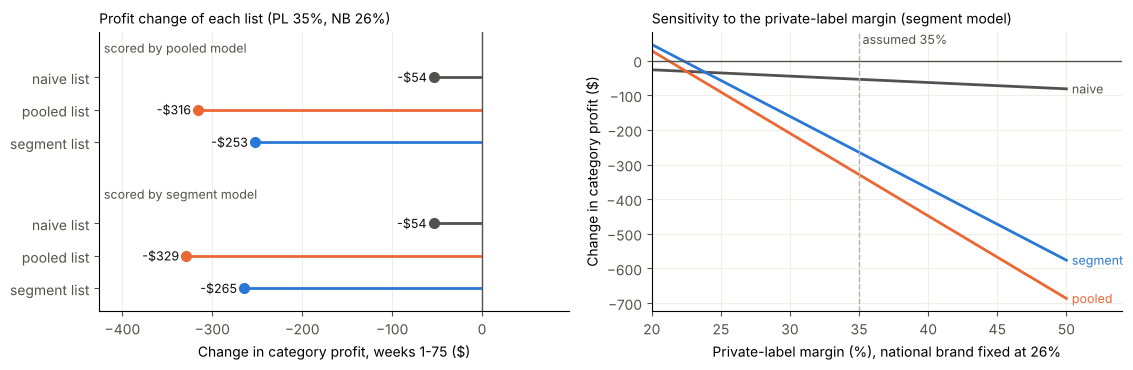

In [8]:
colors = {"naive": "#52514e", "pooled": "#eb6834", "segment": "#2a78d6"}
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.8))
ax = axes[0]; ticks, labels = [], []
for i, ev in enumerate(["pooled model", "segment model"]):
    d = main[main.scored_by == ev].set_index("list"); y0 = i * 4.5
    ax.text(0.01, y0 - 0.9, f"scored by {ev}", fontsize=9, color="#52514e", ha="left", va="center", transform=ax.get_yaxis_transform())
    for k, name in enumerate(["naive", "pooled", "segment"]):
        y = y0 + k; v = d.loc[name, "profit_change"]
        ax.hlines(y, 0, v, color=colors[name], lw=2); ax.plot(v, y, "o", color=colors[name], ms=7)
        ax.text(v, y, (f"  +${v:,.0f}" if v >= 0 else f"-${-v:,.0f}  "), va="center", ha="left" if v >= 0 else "right", fontsize=9, color="#0b0b0b")
        ticks.append(y); labels.append(f"{name} list")
ax.set_yticks(ticks, labels); ax.set_ylim(ticks[-1] + 0.7, -1.4); ax.axvline(0, color="#52514e", lw=1)
lo, hi = main.profit_change.min(), main.profit_change.max(); pad = 0.35 * (hi - lo + 1)
ax.set_xlim(min(lo, 0) - pad, max(hi, 0) + pad)
ax.set_xlabel(f"Change in category profit, weeks 1-75 ($)"); ax.set_title(f"Profit change of each list (PL {M_PL:.0%}, NB {M_NB:.0%})", loc="left", fontsize=10)
ax = axes[1]
for name in ["naive", "pooled", "segment"]:
    v = curves[("segment", name)]; ax.plot(100 * grid_m, v, color=colors[name], lw=2)
    ax.text(100 * grid_m[-1] + 0.4, v[-1], name, color=colors[name], va="center", fontsize=9)
ax.axhline(0, color="#52514e", lw=1); ax.axvline(100 * M_PL, color="#b4b2a9", lw=1, ls="--")
ax.text(100 * M_PL, ax.get_ylim()[1], " assumed 35%", color="#52514e", fontsize=9, va="top")
ax.set_xlim(20, 54); ax.set_xlabel("Private-label margin (%), national brand fixed at 26%"); ax.set_ylabel("Change in category profit ($)")
ax.set_title("Sensitivity to the private-label margin (segment model)", loc="left", fontsize=10)
for a in axes:
    for sp in ["top", "right"]: a.spines[sp].set_visible(False)
    a.tick_params(colors="#52514e")
axes[0].grid(axis="x", color="#eeeeec"); axes[1].grid(color="#eeeeec")
fig.tight_layout(); fig.savefig(OUT / "profit_by_list.png", dpi=150); plt.show()

## 8. Save outputs

In [9]:
table3.to_csv(OUT / "table3_profit_change.csv", index=False)
breakeven.to_csv(OUT / "break_even_private_label_margin.csv", index=False)
flows.to_csv(OUT / "where_removed_demand_goes.csv", index=False)
by_seg.to_csv(OUT / "profit_change_by_segment.csv", index=False)
summary_alt.to_csv(OUT / "profit_per_purchase_by_brand_type.csv")
pd.DataFrame({"alt_id": alt_ids, "private_label": PL.astype(bool), "spend_per_purchase": SPEND, "shelf_value_per_purchase": SHELF,
              "profit_per_purchase_main": PROF}).to_csv(OUT / "alternative_profit.csv", index=False)
print("Saved:", *sorted(p.name for p in OUT.iterdir()), sep="\n  ")

Saved:
  alternative_profit.csv
  break_even_private_label_margin.csv
  profit_by_list.png
  profit_change_by_segment.csv
  profit_per_purchase_by_brand_type.csv
  table3_profit_change.csv
  where_removed_demand_goes.csv


## 9. Reading the result

- Report the **main margins** as the headline and the reference and break-even results as sensitivity.
- If a list's profit sign flips between the main and reference margins, its profit result depends on the assumed private-label margin gap; say so.
- Margins are assumed, not observed. State this as a limitation, with the break-even margins as the honest measure of how much it matters.